# Exploratory Data Analysis: Retail Customer Sales




## 1. Setup and First Look

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi':90,'axes.titleweight':'bold'})
pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.max_columns = 30

raw = pd.read_csv('retail_customer_sales_dataset.csv')
df = raw.copy()         
print('Shape:', raw.shape)
raw.head()

Shape: (7084, 24)


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.00,Male,"62,828.52",West,Gujarat,Surat,Consumer,Grocery,Honey Jar,3,887.94,0.32,"1,811.40","1,204.47",606.93,Debit Card,Standard,3.00,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.00,Male,"50,952.64",North,Haryana,Gurugram,Home Office,Electronics,USB-C Hub,2,"14,309.96",0.18,"23,468.33","17,137.06","6,331.27",Credit Card,Standard,3.00,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.00,Male,"60,476.00",East,Jharkhand,Ranchi,Consumer,Clothing,Winter Jacket,4,710.95,0.09,"2,587.86","1,577.83","1,010.03",Debit Card,Express,3.00,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.00,Male,"41,516.94",West,Gujarat,Surat,Home Office,Grocery,Olive Oil 1L,4,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.00,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.00,Female,"95,727.49",north,Haryana,Gurugram,Consumer,Electronics,Laptop Stand,1,"10,542.13",0.21,"8,328.28","5,528.47","2,799.81",UPI,Express,1.00,Low,No


In [2]:
raw.tail()

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
7079,TXN201768,CUST10870,2024-10-22,2024-10-27,34.00,Male,"79,446.58",East,Odisha,Bhubaneswar,Corporate,Electronics,Laptop Stand,1,"5,395.38",0.09,"4,909.80","3,273.47","1,636.33",Net Banking,Express,2.00,Low,Yes
7080,TXN201737,CUST10314,2024-10-05,2024-10-14,50.00,Male,"21,796.92",East,West Bengal,Durgapur,Home Office,Clothing,Formal Shirt,3,"1,603.82",0.02,"4,715.23","2,923.68","1,791.55",Credit Card,Standard,4.00,High,No
7081,TXN203240,CUST10859,2024-06-04,2024-06-15,42.00,Male,"60,621.27",West,Gujarat,Surat,Consumer,Electronics,Laptop Stand,1,"11,519.59",0.22,"8,985.28","5,360.01","3,625.27",UPI,Standard,2.00,Medium,No
7082,TXN205305,CUST10829,2024-03-31,2024-04-08,32.00,Female,"42,178.47",South,Kerala,Kozhikode,Consumer,Clothing,Running Shoes,3,980.67,0.21,"2,324.19","1,812.17",512.02,UPI,Standard,4.00,High,No
7083,TXN204737,CUST10847,2024-10-18,2024-10-26,63.00,Male,"44,113.29",South,Kerala,Kozhikode,Consumer,Clothing,Denim Jacket,2,"3,727.59",0.30,"5,218.63","3,932.52","1,286.11",Debit Card,Standard,4.00,High,No


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7084 entries, 0 to 7083
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      7084 non-null   str    
 1   Customer_ID         7084 non-null   str    
 2   Order_Date          7084 non-null   str    
 3   Delivery_Date       6978 non-null   str    
 4   Age                 6942 non-null   float64
 5   Gender              7084 non-null   str    
 6   Income              6831 non-null   float64
 7   Region              7084 non-null   str    
 8   State               7084 non-null   str    
 9   City                7084 non-null   str    
 10  Customer_Segment    7084 non-null   str    
 11  Product_Category    7084 non-null   str    
 12  Product             7084 non-null   str    
 13  Quantity            7084 non-null   int64  
 14  Unit_Price          7084 non-null   float64
 15  Discount            7013 non-null   float64
 16  Sales            

**First look:** 7,084 rows x 24 columns. The brief expects approximately 7,000 transactions, so the extra 84 rows may include duplicates (verify by ID before removing). Dates are stored as text (`object`). Missing values occur in Age, Income, Discount, Customer_Rating, Delivery_Date, and Satisfaction_Level.

## 2. Data Quality Audit

### 2.1 Missing values (count and %)

,Missing,Missing_%
Customer_Rating,428,6.04
Income,253,3.57
Satisfaction_Level,179,2.53
Age,142,2.00
Delivery_Date,106,1.50
Discount,71,1.00


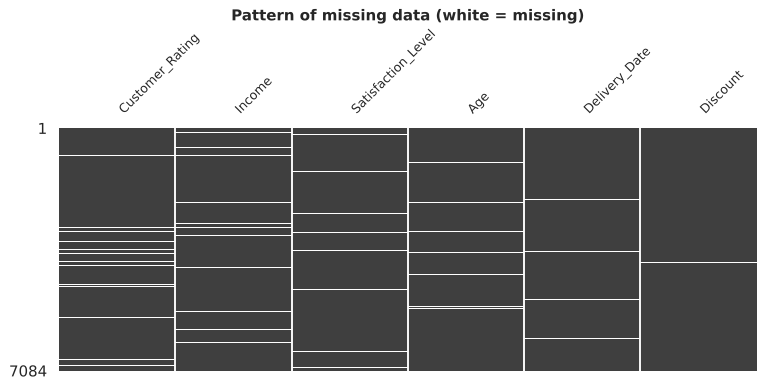

In [4]:
miss = pd.DataFrame({'Missing': raw.isna().sum(), 'Missing_%': raw.isna().mean()*100})
miss = miss[miss.Missing>0].sort_values('Missing', ascending=False)
display(miss)
import missingno as msno
msno.matrix(raw[miss.index], figsize=(10,3.5), sparkline=False, fontsize=10)
plt.title('Pattern of missing data (white = missing)'); plt.show()

Six columns have gaps: **Customer_Rating (6.0%)**, **Income (3.6%)**, **Age (2.0%)**, **Satisfaction_Level (2.5%)**, **Delivery_Date (1.5%)** and **Discount (1.0%)**. Missingness is scattered randomly (no block pattern), so it does not look like a systematic system failure.

### 2.2 Duplicate rows

In [ ]:
print('Exact duplicate rows            :', raw.duplicated().sum())
print('Duplicated Transaction_IDs       :', raw.Transaction_ID.duplicated().sum())
print('Unique Transaction_IDs           :', raw.Transaction_ID.nunique())
hidden = raw[raw.Transaction_ID.duplicated(keep=False) & ~raw.duplicated(keep=False)].sort_values('Transaction_ID')
print('Rows in hidden-duplicate pairs   :', len(hidden))
hidden[['Transaction_ID','Order_Date','Gender','Region','Satisfaction_Level']].head(8)

Exact duplicate rows            : 61
Duplicated Transaction_IDs       : 84
Unique Transaction_IDs           : 7000
Rows in hidden-duplicate pairs   : 46


,Transaction_ID,Order_Date,Gender,Region,Satisfaction_Level
1227,TXN200162,22/07/2024,Female,South,High
1386,TXN200162,2024-07-22,Female,South,High
3392,TXN200221,2023-06-23,female,West,NaN
6761,TXN200221,2023-06-23,Female,West,NaN
3719,TXN200275,30/06/2024,Male,NORTH,NaN
2682,TXN200275,30-Jun-2024,Male,North,NaN
1713,TXN200750,2024-02-11,female,Sth,Medium
2679,TXN200750,2024-02-11,Female,South,Medium


**Finding:** 61 rows are exact duplicates, but **84** Transaction_IDs repeat. The extra 23 are *hidden duplicates*: the same order whose Gender/Region casing or date format differs, so `duplicated()` misses them. They only become visible **after standardisation**, so the cleaning order matters (standardise first, then de-duplicate).

### 2.3 Inconsistent categories

In [6]:
for c in ['Gender','Region']:
    print(c, '->', raw[c].value_counts().to_dict(), '\n')
for c in ['Customer_Segment','Product_Category','Payment_Method','Delivery_Mode','Satisfaction_Level','Returned']:
    print(c, '->', raw[c].dropna().unique().tolist())

Gender -> {'Female': 3585, 'Male': 3232, 'FEMALE': 53, 'female': 53, 'male': 46, 'MALE': 44, 'M': 38, 'F': 33} 

Region -> {'West': 1783, 'East': 1754, 'South': 1741, 'North': 1647, 'east': 30, 'south': 24, 'north': 21, 'Sth': 20, 'WEST': 19, 'Nort': 17, 'west': 15, 'NORTH': 13} 

Customer_Segment -> ['Consumer', 'Home Office', 'Corporate']
Product_Category -> ['Grocery', 'Electronics', 'Clothing', 'Furniture', 'Office Supplies']
Payment_Method -> ['Debit Card', 'Credit Card', 'UPI', 'Cash on Delivery', 'Net Banking']
Delivery_Mode -> ['Standard', 'Express', 'Same-Day']
Satisfaction_Level -> ['Low', 'High', 'Medium']
Returned -> ['No', 'Yes']


**Gender** has 8 spellings (`Male, male, MALE, M, Female, female, FEMALE, F`) and **Region** has 12 (`North, north, NORTH, Nort` and so on, `Sth` for South). The other categorical columns are clean.

### 2.4 Impossible / out-of-range values

In [ ]:
print('Age < 0           :', (raw.Age<0).sum(), raw.Age[raw.Age<0].tolist())
print('Age > 100         :', (raw.Age>100).sum(), raw.Age[raw.Age>100].tolist())
print('Discount < 0      :', (raw.Discount<0).sum(), raw.Discount[raw.Discount<0].tolist())
print('Discount > 0.5    :', (raw.Discount>0.5).sum(), raw.Discount[raw.Discount>0.5].tolist())
print('Quantity <= 0     :', (raw.Quantity<=0).sum())
print('Sales/Cost/Profit <= 0:', ((raw[['Sales','Cost','Profit']]<=0).sum()).to_dict())
print('Rating outside 1-5:', (~raw.Customer_Rating.dropna().between(1,5)).sum())
calc = raw.Quantity*raw.Unit_Price*(1-raw.Discount)
bad = (calc-raw.Sales).abs()/raw.Sales > 0.01
print('Rows where Sales formula breaks:', bad.sum())
raw.loc[bad,['Quantity','Unit_Price','Discount','Sales']]

Age < 0           : 3 [-5.0, -12.0, -1.0]
Age > 100         : 3 [180.0, 999.0, 150.0]
Discount < 0      : 2 [-0.2, -0.1]
Discount > 0.5    : 4 [2.0, 1.1, 1.5, 1.2]
Quantity <= 0     : 0
Sales/Cost/Profit <= 0: {'Sales': 0, 'Cost': 0, 'Profit': 0}


Rating outside 1-5: 0
Rows where Sales formula breaks: 6


,Quantity,Unit_Price,Discount,Sales
1196,3,"2,084.63",-0.20,"4,252.65"
2624,5,"12,394.56",2.00,"55,155.79"
3165,4,977.82,1.10,"3,598.38"
4174,4,"9,160.38",1.50,"33,343.78"
5410,3,324.04,-0.10,505.50
6693,5,"1,052.47",1.20,"5,209.73"


**Finding:** 6 impossible Ages (-12, -5, -1, 150, 180, 999) and 6 impossible Discounts (-0.2, -0.1, 1.1, 1.2, 1.5, 2.0). Notably, the **6 rows where the Sales formula breaks are exactly the 6 invalid discounts**. This means `Sales` itself is trustworthy and we can *recover* the true discount from it (see cleaning).

### 2.5 Date format issues

In [8]:
pattern = lambda s: s.dropna().str.replace(r'[0-9]','9',regex=True).str.replace(r'[A-Za-z]+','Mon',regex=True)
print(pattern(raw.Order_Date).value_counts(), '\n')
print(pattern(raw.Delivery_Date).value_counts())

Order_Date
9999-99-99     6601
99-Mon-9999     161
99/99/9999      161
99-99-9999      161
Name: count, dtype: int64 

Delivery_Date
9999-99-99     6509
99-Mon-9999     158
99/99/9999      156
99-99-9999      155
Name: count, dtype: int64


Both **Order_Date and Delivery_Date use four different formats**: `2023-12-19` (ISO), `19/12/2023`, `12-19-2023` and `19-Dec-2023`. The audit output shows the counts for each pattern in both columns. 

**Key insight (ambiguity):** `07/03/2023` could be 7 March or 3 July. I tested the possible interpretations against logic (delivery should be 0-30 days after order): treating `/` as **dd/mm/yyyy** and `-` as **mm-dd-yyyy** gave **0 unparseable dates and no delivery gaps over 30 days**; every other combination produced dozens of failures. That is the evidence-based choice.

## 3. Data Cleaning (with justification)

### Step 1: Standardise categories

In [9]:
df['Gender'] = df.Gender.str.strip().str.lower().map({'male':'Male','m':'Male','female':'Female','f':'Female'})
df['Region'] = df.Region.str.strip().str.lower().map({'north':'North','nort':'North','south':'South','sth':'South','east':'East','west':'West'})
print(df.Gender.value_counts(dropna=False).to_dict()); print(df.Region.value_counts(dropna=False).to_dict())

{'Female': 3724, 'Male': 3360}
{'West': 1817, 'South': 1785, 'East': 1784, 'North': 1698}


**Why:** a mapping (not `.title()`) is used because `M`, `F`, `Nort`, `Sth` are abbreviations that casing alone cannot fix. `assert` below confirms nothing was left unmapped.

In [10]:
assert df.Gender.notna().all() and df.Region.notna().all()

### Step 2: Parse dates (4 formats) into datetime

In [11]:
def parse_dates(s):
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    rules = [(r'^\d{4}-',        '%Y-%m-%d'),   # 2023-12-19
             (r'^\d\d/',         '%d/%m/%Y'),   # 19/12/2023
             (r'^\d\d-\d\d-',    '%m-%d-%Y'),   # 12-19-2023
             (r'^\d\d-[A-Za-z]', '%d-%b-%Y')]   # 19-Dec-2023
    for pat, fmt in rules:
        m = s.str.match(pat, na=False)
        out[m] = pd.to_datetime(s[m], format=fmt, errors='coerce')
    return out
df['Order_Date']    = parse_dates(raw.Order_Date)
df['Delivery_Date'] = parse_dates(raw.Delivery_Date)
print('Unparsed Order_Date:', df.Order_Date.isna().sum(), '| Order range:', df.Order_Date.min().date(), 'to', df.Order_Date.max().date())

Unparsed Order_Date: 0 | Order range: 2023-01-01 to 2024-12-31


### Step 3: Remove duplicates (after standardising)

In [ ]:
before = len(df)
df['_nulls'] = df.isna().sum(axis=1)
df = (df.sort_values(['Transaction_ID','_nulls']).drop_duplicates('Transaction_ID', keep='first')
        .drop(columns='_nulls').sort_index().reset_index(drop=True))
print(f'Rows before: {before:,} | after: {len(df):,} | removed: {before-len(df)}')
assert df.Transaction_ID.is_unique

Rows before: 7,084 | after: 7,000 | removed: 84


**Why:** a transaction ID must be unique, so repeats are double-entries and would inflate revenue. Where two copies differed (one had a missing value), the more complete one is kept so no information is lost.

### Step 4: Impossible values, recover instead of guessing

In [ ]:
inv = (df.Discount<0)|(df.Discount>0.5)
df['Discount_Imputed'] = inv | df.Discount.isna()
implied = 1 - df.Sales/(df.Quantity*df.Unit_Price)
df.loc[df.Discount_Imputed,'Discount'] = implied[df.Discount_Imputed].round(2)
print('Discounts recovered:', df.Discount_Imputed.sum(), '| valid range now:', df.Discount.min(), '-', df.Discount.max())


df.loc[(df.Age<18)|(df.Age>100),'Age'] = np.nan
df['Age_Imputed'] = df.Age.isna()
df['Age'] = df.Age.fillna(df.groupby('Customer_ID').Age.transform('median'))
df['Age'] = df.Age.fillna(df.groupby('Customer_Segment').Age.transform('median'))   

df['Income_Imputed'] = df.Income.isna()
df['Income'] = df.Income.fillna(df.groupby('Customer_ID').Income.transform('median'))
df['Income'] = df.Income.fillna(df.groupby('Customer_Segment').Income.transform('median'))
print('Age min/max:', df.Age.min(), df.Age.max(), '| Remaining nulls Age/Income/Discount:', df[['Age','Income','Discount']].isna().sum().tolist())
print('Age imputed:', df.Age_Imputed.sum(), '| Income imputed:', df.Income_Imputed.sum())

Discounts recovered: 76 | valid range now: 0.0 - 0.5
Age min/max: 18.0 72.0 | Remaining nulls Age/Income/Discount: [0, 0, 0]
Age imputed: 146 | Income imputed: 245


**Why this is smarter than a global mean:** a customer's age and income do not change between orders, so the *same customer's other rows* are the best possible estimate. Only if a customer has a single order do we fall back to the segment **median** (median, not mean, because Income is heavily right-skewed). Every imputed row is **flagged** (`*_Imputed`) so the change is auditable.

### Step 5: Delivery dates and remaining missing values

In [ ]:
df['Delivery_Days'] = (df.Delivery_Date - df.Order_Date).dt.days
df['Delivery_Date_Error'] = df.Delivery_Days < 0
print('Delivery before order (data error):', df.Delivery_Date_Error.sum())
print('Delivery_Date missing:', df.Delivery_Date.isna().sum())

df.loc[df.Delivery_Date_Error, ['Delivery_Date','Delivery_Days']] = [pd.NaT, np.nan]


df['Rated'] = df.Customer_Rating.notna()

df['Satisfaction_Level'] = df.Satisfaction_Level.fillna('Not Recorded')
print(df.isna().sum()[lambda s: s>0])

Delivery before order (data error): 15
Delivery_Date missing: 105
Delivery_Date      120
Customer_Rating    420
Delivery_Days      120
dtype: int64


| Column | Problem | Decision | Reason |
|---|---|---|---|
| Gender / Region | 8 / 12 spellings | Map to canonical labels | Abbreviations need mapping, not casing |
| Order/Delivery_Date | 4 formats | Parse with evidence-tested rules | Wrong guess would shift months |
| Duplicates | 84 repeat IDs | Drop, keep most complete | Avoid double-counting revenue |
| Discount | 6 invalid + 71 null | **Recompute from Sales formula** | Exact recovery, no guessing |
| Age | 6 invalid + 142 null | Customer's own median, then segment median | Age is stable per customer |
| Income | 253 null | Customer's own value, then segment median | Skewed, so median not mean |
| Delivery_Date | 15 before order, ~106 null | Set to NaN, keep row | True date unknowable; sales still valid |
| Customer_Rating | ~6% null | Keep NaN + `Rated` flag | Non-response is genuine |
| Satisfaction_Level | ~2.5% null | `Not Recorded` | Do not invent opinions |

## 4. Descriptive Statistics and Univariate Analysis

In [15]:
key = ['Age','Income','Quantity','Unit_Price','Discount','Sales','Cost','Profit']
d = df[key]
stats = pd.DataFrame({
  'Mean':d.mean(),'Median':d.median(),'Mode':d.round(2).mode().iloc[0],'Std Dev':d.std(),'Variance':d.var(),
  'Min':d.min(),'P25 (Q1)':d.quantile(.25),'P75 (Q3)':d.quantile(.75),'IQR':d.quantile(.75)-d.quantile(.25),
  'P90':d.quantile(.90),'P95':d.quantile(.95),'P99':d.quantile(.99),'Max':d.max(),'Skewness':d.skew(),'Kurtosis':d.kurt()}).T
stats

,Age,Income,Quantity,Unit_Price,Discount,Sales,Cost,Profit
Mean,36.05,"55,049.38",3.01,"4,519.23",0.20,"10,961.60","7,371.90","3,589.70"
Median,36.00,"48,846.62",3.00,"2,261.47",0.18,"4,825.56","3,229.89","1,528.70"
Mode,18.00,"15,000.00",2.00,122.04,0.13,258.73,217.28,19.47
Std Dev,10.41,"36,971.39",1.41,"4,893.21",0.12,"14,549.03","9,878.00","4,928.02"
Variance,108.30,"1,366,883,415.46",1.99,"23,943,479.34",0.01,"211,674,394.52","97,574,874.12","24,285,381.42"
Min,18.00,"15,000.00",1.00,51.53,0.00,28.70,19.53,9.17
P25 (Q1),29.00,"37,125.40",2.00,895.92,0.11,"1,815.46","1,210.18",574.08
P75 (Q3),43.00,"65,721.73",4.00,"7,244.51",0.27,"14,095.35","9,494.70","4,533.28"
IQR,14.00,"28,596.33",2.00,"6,348.58",0.16,"12,279.89","8,284.52","3,959.20"
P90,50.00,"85,498.90",5.00,"12,764.73",0.37,"30,582.88","20,630.78","9,834.10"


**Reading the table in business terms:** for `Sales`, the **mean is far above the median**, so a small number of very large orders pull the average up and the *typical* order is much smaller than the average suggests. Reporting the median is more honest for planning.

### 4.1 Distribution shape (numerical)

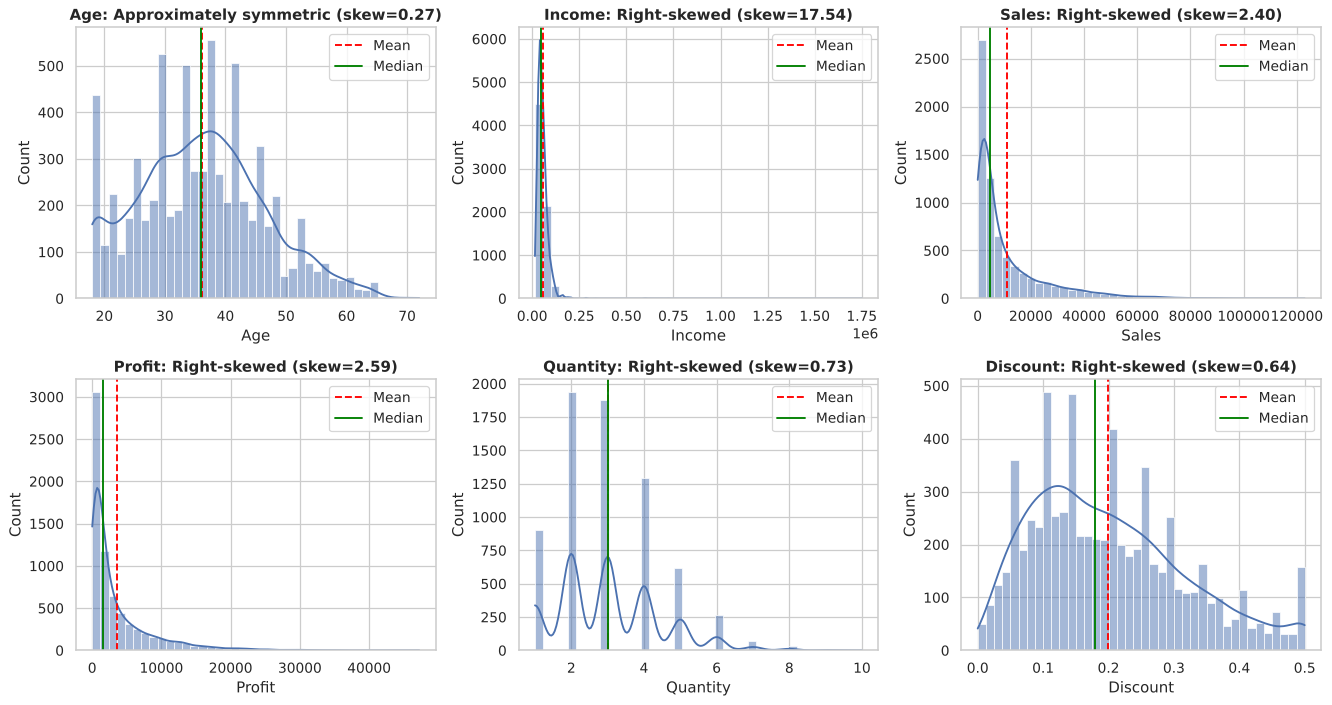

In [16]:
def shape(s):
    k=s.skew(); return 'Right-skewed' if k>0.5 else ('Left-skewed' if k<-0.5 else 'Approximately symmetric')
fig, ax = plt.subplots(2,3, figsize=(15,8))
for a,c in zip(ax.ravel(), ['Age','Income','Sales','Profit','Quantity','Discount']):
    sns.histplot(df[c], bins=40, kde=True, ax=a, color=sns.color_palette()[0])
    a.axvline(df[c].mean(), color='red', ls='--', label='Mean'); a.axvline(df[c].median(), color='green', ls='-', label='Median')
    a.set_title(f'{c}: {shape(df[c])} (skew={df[c].skew():.2f})'); a.legend()
plt.tight_layout(); plt.show()

| Variable | Shape | Business meaning |
|---|---|---|
| **Age** | Roughly symmetric | Customer base is centred around the mid-30s; no age group dominates abnormally |
| **Income** | Strongly right-skewed | Most customers earn modestly; a few very high earners stretch the average, so use the median |
| **Sales** | Strongly right-skewed | Many small everyday orders plus a few very large Electronics/Furniture orders drive revenue |
| **Profit** | Strongly right-skewed | Profit follows order size: the big orders are the profit engine |
| **Quantity / Discount** | Mild right tail | Most orders are 2-3 units; typical discount is 10-30% and tapers off towards the 50% cap |

### 4.2 Categorical variables: frequency and proportion

,Count,Share_%
Region,,
West,1798,25.70
East,1765,25.20
South,1761,25.20
North,1676,23.90


,Count,Share_%
Product_Category,,
Electronics,1975,28.20
Grocery,1669,23.80
Clothing,1533,21.90
Furniture,979,14.00
Office Supplies,844,12.10


,Count,Share_%
Customer_Segment,,
Consumer,3840,54.90
Corporate,2114,30.20
Home Office,1046,14.90


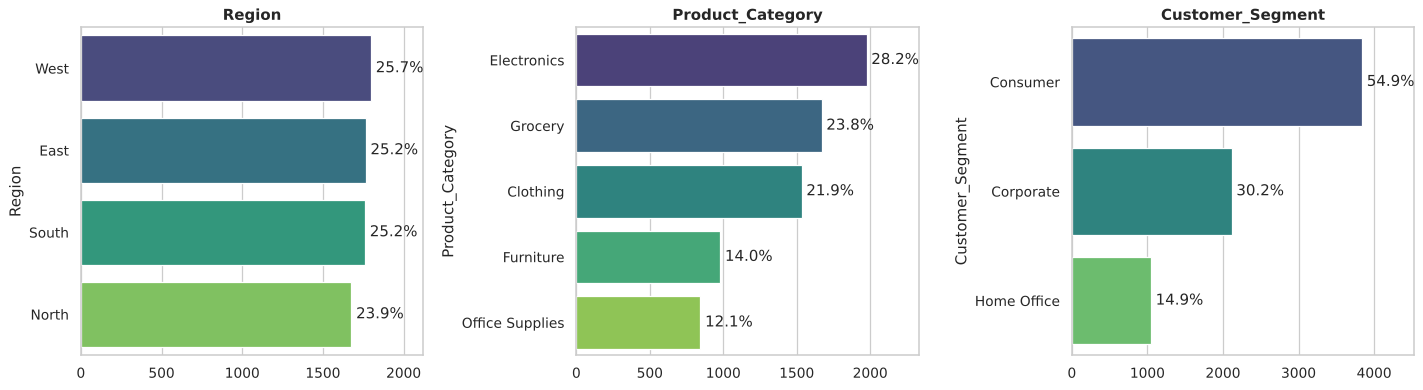

In [17]:
fig, ax = plt.subplots(1,3, figsize=(16,4.5))
for a,c in zip(ax, ['Region','Product_Category','Customer_Segment']):
    f = df[c].value_counts(); p = (f/f.sum()*100).round(1)
    display(pd.DataFrame({'Count':f,'Share_%':p}))
    sns.barplot(x=f.values, y=f.index, ax=a, palette='viridis')
    for i,(v,pp) in enumerate(zip(f.values,p.values)): a.text(v, i, f' {pp}%', va='center')
    a.set_title(c); a.set_xlim(0, f.max()*1.18)
plt.tight_layout(); plt.show()

**Observations:** the four regions are almost evenly balanced (24-26% of orders each); **Electronics** is the largest category by order count (28%); **Consumers** are 55% of orders and Corporate 30%.

## 5. Outlier Detection (IQR and Z-score)

In [18]:
def iqr_flags(s):
    q1,q3=s.quantile([.25,.75]); i=q3-q1; return (s<q1-1.5*i)|(s>q3+1.5*i), q1-1.5*i, q3+1.5*i
rows=[]
for c in ['Sales','Profit','Age','Income']:
    f,lo,hi = iqr_flags(df[c]); z=((df[c]-df[c].mean())/df[c].std()).abs()>3
    rows.append([c, f.sum(), f.mean()*100, lo, hi, z.sum()])
    df[f'{c}_Outlier'] = f
pd.DataFrame(rows, columns=['Variable','IQR outliers','% of rows','Lower fence','Upper fence','Z>3 outliers']).set_index('Variable')

,IQR outliers,% of rows,Lower fence,Upper fence,Z>3 outliers
Variable,,,,,
Sales,632,9.03,"-16,604.37","32,515.17",153
Profit,640,9.14,"-5,364.72","10,472.09",160
Age,10,0.14,8.00,64.00,6
Income,236,3.37,"-5,769.09","108,616.22",41


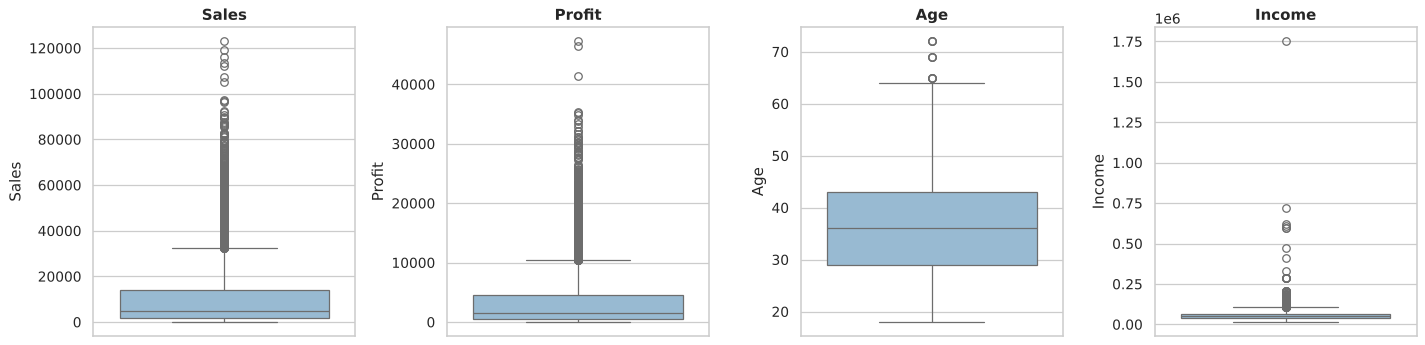

In [19]:
fig, ax = plt.subplots(1,4, figsize=(16,4))
for a,c in zip(ax, ['Sales','Profit','Age','Income']):
    sns.boxplot(y=df[c], ax=a, color='#8fbcdb'); a.set_title(c)
plt.tight_layout(); plt.show()

### Are these outliers real or errors?

In [20]:
print('Sales outliers by category (%) :'); print((df[df.Sales_Outlier].Product_Category.value_counts(normalize=True)*100).round(1).to_dict())
print('Sales outliers by segment  (%) :'); print((df[df.Sales_Outlier].Customer_Segment.value_counts(normalize=True)*100).round(1).to_dict())
print('Sales outliers - avg Quantity   :', round(df[df.Sales_Outlier].Quantity.mean(),2), ' vs overall', round(df.Quantity.mean(),2))
print('Sales outliers - avg Unit_Price :', round(df[df.Sales_Outlier].Unit_Price.mean()), ' vs overall', round(df.Unit_Price.mean()))
m = (df.Profit/df.Sales)
print('Profit margin of sales outliers :', round(m[df.Sales_Outlier].mean()*100,1),'% vs overall', round(m.mean()*100,1),'%')
print('\nIncome outliers:', df.Income_Outlier.sum(), '| >5 lakh:', (df.Income>500000).sum(), '| max:', f'{df.Income.max():,.0f}')
print(df.loc[df.Income>500000, ['Customer_ID','Income','Customer_Segment']].drop_duplicates('Customer_ID'))

Sales outliers by category (%) :
{'Electronics': 52.5, 'Furniture': 47.5}
Sales outliers by segment  (%) :
{'Consumer': 52.4, 'Corporate': 32.9, 'Home Office': 14.7}
Sales outliers - avg Quantity   : 4.39  vs overall 3.01
Sales outliers - avg Unit_Price : 13602  vs overall 4519
Profit margin of sales outliers : 32.8 % vs overall 32.6 %

Income outliers: 236 | >5 lakh: 6 | max: 1,750,890
     Customer_ID       Income Customer_Segment
99     CUST10006   622,289.57         Consumer
747    CUST11202   598,321.39        Corporate
1723   CUST10854   721,081.66        Corporate
4597   CUST10770   606,984.57         Consumer
4765   CUST10285   595,873.84      Home Office
6850   CUST11124 1,750,890.41      Home Office


**Judgement:**
- **Sales and Profit outliers = genuine.** They come from high-priced Electronics/Furniture items and bulk quantities, and their profit margin is normal, because Sales, Cost and Profit reconcile exactly in every row (`Sales - Cost = Profit`). They are big *real* orders, so they are **kept**. Removing them would delete the most valuable customers.
- **Age outliers:** none remain after cleaning (the 6 impossible values were the only errors).
- **Income outliers = mostly genuine skew**, but the value **~17.5 lakh** is about 2.4x the next-largest (7.2 lakh) and appears only once, so it is a *likely entry error (extra digit)*. All are **flagged (`Income_Outlier`) rather than deleted**, and Income-based comparisons should use the median.

## 6. Feature Engineering and Business Questions

### 6.1 Calculated columns

In [21]:
df['Profit_Margin_%'] = df.Profit / df.Sales * 100                                  # 1. profitability of the order
df['Order_Year']      = df.Order_Date.dt.year                                       # 2. time features
df['Order_Month']     = df.Order_Date.dt.to_period('M').astype(str)
df['Order_Quarter']   = df.Order_Date.dt.to_period('Q').astype(str)
df['Order_Weekday']   = df.Order_Date.dt.day_name()
# 3. Delivery_Days was created in Step 5 = Delivery_Date - Order_Date
df['Revenue_per_Customer'] = df.groupby('Customer_ID').Sales.transform('sum')       # 4. lifetime value of the buyer
df['Orders_per_Customer']  = df.groupby('Customer_ID').Transaction_ID.transform('count')
df['Discount_Band'] = pd.cut(df.Discount,[-0.001,.10,.20,.30,.40,.50],labels=['0-10%','10-20%','20-30%','30-40%','40-50%'])  # 5
df['Age_Group'] = pd.cut(df.Age,[17,25,35,45,55,100],labels=['18-25','26-35','36-45','46-55','56+'])                          # 6
df['Order_Size'] = pd.qcut(df.Sales,4,labels=['Small','Medium','Large','Very Large'])                                        # 7
df['Late_Delivery'] = df.Delivery_Days > 10                                          # 8
df[['Transaction_ID','Profit_Margin_%','Delivery_Days','Revenue_per_Customer','Discount_Band','Age_Group','Order_Size']].head()

,Transaction_ID,Profit_Margin_%,Delivery_Days,Revenue_per_Customer,Discount_Band,Age_Group,Order_Size
0,TXN205933,33.51,6.00,"5,003.25",30-40%,36-45,Small
1,TXN201247,26.98,4.00,"74,411.80",10-20%,36-45,Very Large
2,TXN202714,39.03,8.00,"100,342.46",0-10%,36-45,Medium
3,TXN206797,36.57,4.00,"29,951.36",30-40%,26-35,Small
4,TXN203937,33.62,7.00,"21,572.93",20-30%,26-35,Large


### 6.2 Business questions (groupby and aggregation)

**Q1. Which region has the highest average order value, and which brings in the most revenue?**

,Orders,Total_Sales,Avg_Order_Value,Median_Order,Total_Profit
Region,,,,,
East,1765,"20,018,192.35","11,341.75","5,029.99","6,607,664.00"
West,1798,"19,758,995.56","10,989.43","4,872.94","6,472,920.07"
South,1761,"18,890,109.55","10,726.92","4,747.23","6,177,763.05"
North,1676,"18,063,891.81","10,777.98","4,628.11","5,869,535.54"


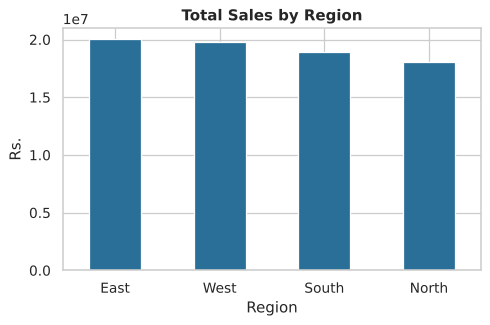

In [22]:
q1 = df.groupby('Region').agg(Orders=('Sales','size'), Total_Sales=('Sales','sum'), Avg_Order_Value=('Sales','mean'),
                              Median_Order=('Sales','median'), Total_Profit=('Profit','sum')).sort_values('Total_Sales', ascending=False)
display(q1)
q1.Total_Sales.plot.bar(color='#2a6f97', figsize=(6,3.5), title='Total Sales by Region'); plt.ylabel('Rs.'); plt.xticks(rotation=0); plt.show()

**Insight:** East leads on revenue (Rs. 2.00 crore) and average order value (Rs. 11,342), but the gap to the lowest region (South, Rs. 10,727) is only ~6%. Regions are *balanced*; growth must come from categories/segments, not from fixing a weak region. **Caveat:** East's lead is driven by a few large orders; its *median* order is also highest (Rs. 5,030), so the lead is not just outliers.

**Q2. Which product category has the lowest profit margin?**

,Sales,Profit,Avg_Discount,Margin_%
Product_Category,,,,
Clothing,"7,781,680.39","2,521,027.84",0.20,32.40
Office Supplies,"2,566,182.51","832,190.36",0.20,32.43
Grocery,"2,685,875.10","874,840.19",0.20,32.57
Furniture,"26,057,893.88","8,547,604.77",0.19,32.80
Electronics,"37,639,557.39","12,352,219.50",0.20,32.82


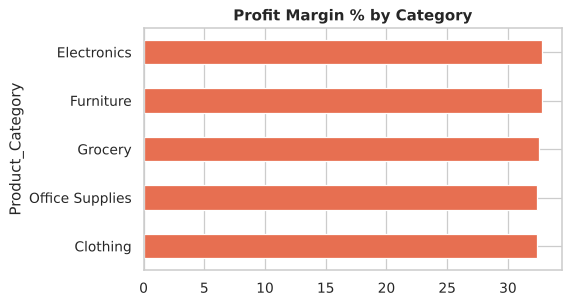

In [23]:
q2 = df.groupby('Product_Category').agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Avg_Discount=('Discount','mean'))
q2['Margin_%'] = q2.Profit/q2.Sales*100
q2 = q2.sort_values('Margin_%'); display(q2)
q2['Margin_%'].plot.barh(color='#e76f51', figsize=(6,3.5), title='Profit Margin % by Category'); plt.show()

**Insight:** Clothing has the lowest margin (32.4%), but the range across all five categories is only **0.4 percentage points** (32.4-32.8%). Margin is practically identical everywhere, so there is no 'weak' category on margin. Profit therefore follows revenue: **Electronics (49%) + Furniture (34%) = 83% of all sales**, while Grocery + Office Supplies bring just 7% of sales from 36% of orders. These small-ticket categories need many orders to earn little; their handling cost per order deserves review.

**Q3. Which customer segment is the most valuable?**

In [24]:
q3 = df.groupby('Customer_Segment').agg(Orders=('Sales','size'), Customers=('Customer_ID','nunique'), Total_Sales=('Sales','sum'),
        Avg_Order=('Sales','mean'), Total_Profit=('Profit','sum'))
q3['Sales_Share_%']=q3.Total_Sales/q3.Total_Sales.sum()*100; q3['Order_Share_%']=q3.Orders/q3.Orders.sum()*100
q3.sort_values('Total_Sales', ascending=False)

,Orders,Customers,Total_Sales,Avg_Order,Total_Profit,Sales_Share_%,Order_Share_%
Customer_Segment,,,,,,,
Consumer,3840,1437,"41,718,896.33","10,864.30","13,703,577.36",54.37,54.86
Corporate,2114,1186,"23,551,202.48","11,140.59","7,665,257.93",30.69,30.20
Home Office,1046,796,"11,461,090.46","10,957.07","3,759,047.37",14.94,14.94


**Insight:** Consumers generate 54% of sales, Corporate 31%, Home Office 15%. Order value is similar across segments (Corporate is highest at Rs. 11,141 vs Consumer Rs. 10,864), so Corporate is not buying meaningfully bigger baskets. Segment share simply mirrors order share.

**Q4. Does heavier discounting actually earn more or just cut margin?**

In [25]:
q4 = df.groupby('Discount_Band').agg(Orders=('Sales','size'), Avg_Sales=('Sales','mean'), Avg_Margin_pct=('Profit_Margin_%','mean'), Return_Rate=('Returned', lambda s:(s=='Yes').mean()*100))
display(q4)
print('Correlation Discount vs Margin :', round(df.Discount.corr(df['Profit_Margin_%']),3))
print('Correlation Discount vs Quantity:', round(df.Discount.corr(df.Quantity),3))

,Orders,Avg_Sales,Avg_Margin_pct,Return_Rate
Discount_Band,,,,
0-10%,1668,"13,085.47",32.59,12.95
10-20%,2329,"11,541.64",32.68,11.29
20-30%,1679,"10,409.74",32.72,14.29
30-40%,855,"8,347.70",32.54,12.40
40-50%,469,"7,268.45",32.33,11.73


Correlation Discount vs Margin : -0.005
Correlation Discount vs Quantity: -0.001


**Insight:** Average margin is about 32.6% across discount bands. In this dataset, the correlations of discount with margin (-0.005) and quantity (-0.001) are near zero; this observational pattern does not establish that discounts have no effect on demand. Average sales per order is lower in the 40-50% discount band than in the 0-10% band, but that comparison does not isolate a discount effect. **Caveat for an analyst:** Cost is recorded at 55-80% of the *discounted* sales value, so the data cannot show margin erosion from discounting. Management should verify costs against list price before concluding that discounts are free.

**Q5. Which product category and delivery mode have the highest return rate?**

In [26]:
df['Is_Returned'] = (df.Returned=='Yes').astype(int)
display((df.groupby('Product_Category').Is_Returned.mean()*100).round(2).sort_values(ascending=False).to_frame('Return_Rate_%'))
display((df.groupby('Delivery_Mode').Is_Returned.mean()*100).round(2).sort_values(ascending=False).to_frame('Return_Rate_%'))
print('Overall return rate:', round(df.Is_Returned.mean()*100,2),'%')
print('Revenue tied to returned orders: Rs.', f'{df[df.Returned=="Yes"].Sales.sum():,.0f}', f'({df[df.Returned=="Yes"].Sales.sum()/df.Sales.sum()*100:.1f}% of sales)')

,Return_Rate_%
Product_Category,
Clothing,13.50
Furniture,13.18
Grocery,12.46
Electronics,12.10
Office Supplies,11.49


,Return_Rate_%
Delivery_Mode,
Same-Day,12.79
Standard,12.61
Express,12.41


Overall return rate: 12.57 %
Revenue tied to returned orders: Rs. 9,037,761 (11.8% of sales)


**Insight:** 12.6% of orders (11.8% of sales, about Rs. 90 lakh) are returned. Return rates are similar across categories (11.5-13.5%, Clothing highest) and delivery modes (12.4-12.8%), so returns look like a *business-wide* issue rather than a product- or delivery-specific one. Differences of 1-2 points between groups should not be over-read without a significance test.

**Q6. How does delivery speed relate to customer rating and returns?**

In [27]:
q6 = df.groupby('Delivery_Mode').agg(Avg_Delivery_Days=('Delivery_Days','mean'), Avg_Rating=('Customer_Rating','mean'), Orders=('Sales','size'))
display(q6)
print('Correlation Delivery_Days vs Rating:', round(df.Delivery_Days.corr(df.Customer_Rating),3))
display(df.groupby(df.Late_Delivery.map({True:'Late (>10 days)',False:'On time'})).agg(Avg_Rating=('Customer_Rating','mean'), Return_Rate=('Is_Returned','mean')))

,Avg_Delivery_Days,Avg_Rating,Orders
Delivery_Mode,,,
Express,5.63,3.11,2055
Same-Day,5.77,3.12,696
Standard,5.65,3.08,4249


Correlation Delivery_Days vs Rating: -0.014


,Avg_Rating,Return_Rate
Late_Delivery,,
Late (>10 days),3.10,0.15
On time,3.09,0.12


**Insight (important):** Recorded average delivery durations are similar in this dataset: Express (5.6 days), Same-Day (5.8 days) and Standard (5.7 days), with a median of 6 days for each. The correlation between recorded delivery days and rating is -0.014, indicating little linear association in this sample, not proof that no relationship exists. These observational results do not establish that premium modes fail to provide faster service; inconsistent timestamps or mode definitions could affect the comparison. Only 4.7% of orders take more than 10 days. Validate delivery records and service definitions before making claims about speed.

**Q7. Is the business growing, and is there seasonality?**

,Sales,Profit,Orders,Growth_%
Order_Year,,,,
2023,"38,655,639.29","12,509,509.31",3525,NaN
2024,"38,075,549.98","12,618,373.35",3475,-1.50


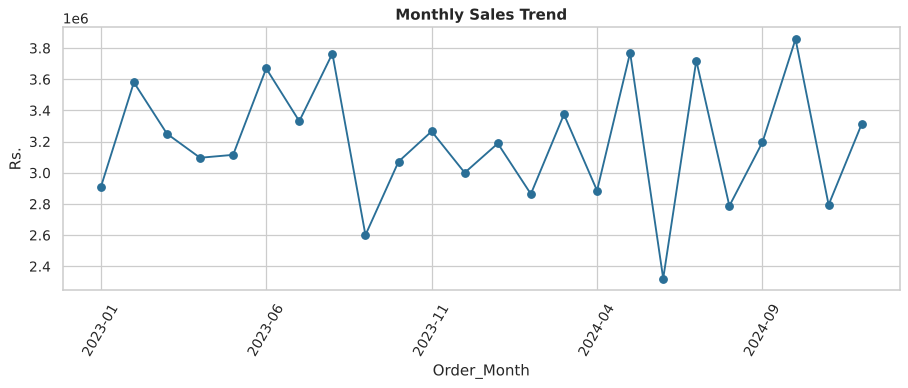

Best month : 2024-10 (Rs.3,857,736) | Weakest: 2024-06


In [28]:
yr = df.groupby('Order_Year').agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Orders=('Sales','size')); yr['Growth_%']=yr.Sales.pct_change()*100; display(yr)
mon = df.groupby('Order_Month').Sales.sum()
ax = mon.plot(marker='o', figsize=(12,3.8), color='#2a6f97', title='Monthly Sales Trend'); ax.set_ylabel('Rs.'); plt.xticks(rotation=60); plt.show()
print('Best month :', mon.idxmax(), f'(Rs.{mon.max():,.0f})', '| Weakest:', mon.idxmin())

**Insight:** Sales fell 1.5% from 2023 (Rs. 3.87 crore) to 2024 (Rs. 3.81 crore): the business is **flat, not growing**. Seasonality is mild (each month is 7.6-9.2% of annual sales); peak was October 2024 (Rs. 38.6 lakh) and the weakest June 2024 (Rs. 23.2 lakh). The 2024 dip came mostly from West (-8.5%) while North grew 7%.

**Q8. How concentrated is revenue? (Pareto: do a few customers drive most sales?)**

Customers: 1,576 | Top 10% of customers generate 26.7% of revenue
Top 5 customers:


,Total_Sales
Customer_ID,
CUST11430,"254,002.26"
CUST10354,"238,064.84"
CUST10459,"221,690.61"
CUST10302,"219,114.52"
CUST10970,"218,118.79"


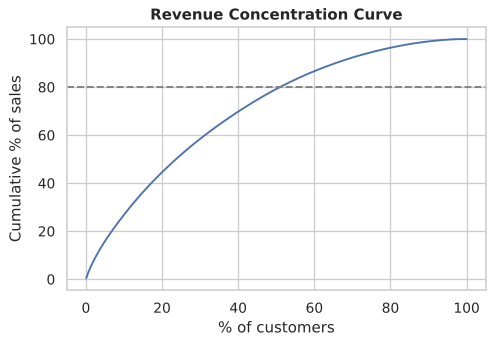

In [29]:
cust = df.groupby('Customer_ID').Sales.sum().sort_values(ascending=False)
top10pct = cust.head(int(len(cust)*0.1)).sum()/cust.sum()*100
print(f'Customers: {len(cust):,} | Top 10% of customers generate {top10pct:.1f}% of revenue')
print('Top 5 customers:'); display(cust.head(5).to_frame('Total_Sales'))
cum = cust.cumsum()/cust.sum()*100
plt.figure(figsize=(6,3.8)); plt.plot(np.arange(1,len(cum)+1)/len(cum)*100, cum.values); plt.axhline(80,ls='--',c='grey')
plt.xlabel('% of customers'); plt.ylabel('Cumulative % of sales'); plt.title('Revenue Concentration Curve'); plt.show()

**Insight:** The top 10% of customers generate **26.7%** of revenue, which is far less concentrated than the classic 80/20 rule. Revenue is spread across 1,576 customers (avg 4.4 orders each), so the business is not dangerously dependent on a handful of accounts. By *order size*, however, the biggest quarter of orders (above Rs. 14,109) delivers **71% of revenue**.

**Q9. Does payment method or age group change buying behaviour?**

,Orders,Avg_Order,Return_Rate_pct
Payment_Method,,,
Cash on Delivery,1408,"11,559.30",13.14
Credit Card,1337,"10,944.76",11.52
Debit Card,1417,"10,935.95",12.14
Net Banking,1433,"10,127.40",11.93
UPI,1405,"11,255.33",14.09


,Orders,Avg_Order,Avg_Margin
Age_Group,,,
18-25,1181,"11,437.47",32.20
26-35,2215,"11,018.65",32.77
36-45,2335,"10,735.66",32.75
46-55,983,"10,892.11",32.55
56+,286,"10,638.20",32.59


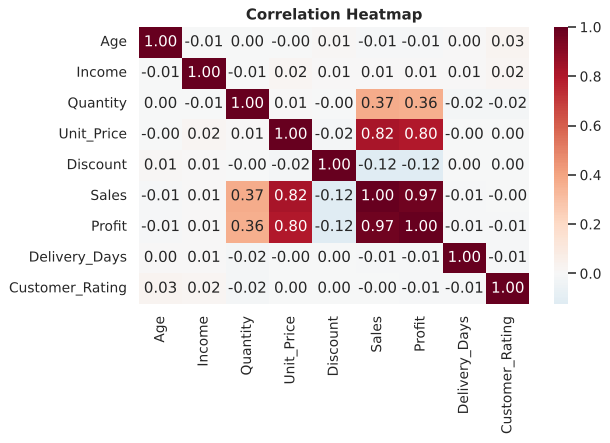

In [30]:
display(df.groupby('Payment_Method').agg(Orders=('Sales','size'), Avg_Order=('Sales','mean'), Return_Rate_pct=('Is_Returned', lambda s:s.mean()*100)).round(2))
display(df.groupby('Age_Group').agg(Orders=('Sales','size'), Avg_Order=('Sales','mean'), Avg_Margin=('Profit_Margin_%','mean')).round(2))
plt.figure(figsize=(7,4)); sns.heatmap(df[['Age','Income','Quantity','Unit_Price','Discount','Sales','Profit','Delivery_Days','Customer_Rating']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation Heatmap'); plt.show()

**Insight:** Cash on Delivery has the highest average order (Rs. 11,559) and Net Banking the lowest (Rs. 10,127), a ~14% gap. Age groups and payment methods show only modest differences. In the heatmap, Sales/Profit correlate strongly with Unit_Price (large-ticket items drive revenue), while Age, Income, Discount and Rating show almost no relationship with spending.

## 7. Save Cleaned Dataset

In [31]:
out = df.drop(columns=['Is_Returned'])
out.to_csv('cleaned_retail_customer_sales_dataset.csv', index=False)
print('Saved:', out.shape, '| Remaining nulls:', out.isna().sum()[lambda s:s>0].to_dict())

Saved: (7000, 45) | Remaining nulls: {'Delivery_Date': 120, 'Customer_Rating': 420, 'Delivery_Days': 120}


## 8. Key Findings Summary
1. **Data quality:** 84 duplicate transactions, 8 gender and 12 region spellings, 4 date formats, 12 impossible values and ~800 nulls were found; all were fixed or flagged (7,084 to 7,000 rows).
2. **Revenue is concentrated in big-ticket items:** Electronics + Furniture = 83% of sales; the largest 25% of orders = 71% of sales. Mean order (Rs. 10,962) is 2.3x the median (Rs. 4,826).
3. **Margin is uniform (~32.7%)** across categories, regions, segments and discount levels, so profit follows revenue.
4. **Discounts show little observed association with volume or margin:** correlations with quantity and margin are near zero in this dataset; this does not establish a causal effect.
5. **Recorded delivery times are similar across modes:** Express, Same-Day and Standard average about 5.7 days in this dataset; validate timestamps and service definitions before concluding the modes are equivalent.
6. **12.6% of orders are returned** (11.8% of sales), evenly across categories and modes.
7. **Sales are flat** (-1.5% YoY) with mild seasonality, and revenue is well spread across customers (top 10% = 27%).

**Limitations:** dates with `/` and `-` were interpreted as dd/mm and mm-dd using logical validation (not metadata); Income outliers were flagged, not removed; correlation does not imply causation.

## 9. Test Cases (10 automated checks on the cleaned data)
A cleaning step is only trustworthy if it can be *verified*. Each test below asserts one property the cleaned dataset **must** satisfy. The same tests are saved in `tests/test_cleaned_data.py` and run with `pytest tests/ -v`.

| # | Test | What it proves |
|---|---|---|
| 1 | 7,000 rows, unique Transaction_ID | Duplicates fully removed |
| 2 | No fully duplicated rows | No hidden repeats |
| 3 | Gender in {Male, Female} | Spelling standardised |
| 4 | Region in {North, South, East, West} | Spelling standardised |
| 5 | Age 18-100, no nulls in Age/Income | Impossible and missing values handled |
| 6 | Discount 0-0.5, no nulls | Invalid discounts recovered |
| 7 | Dates are datetime, within 2023-2024 | Mixed formats parsed correctly |
| 8 | Delivery never before order | Date logic errors removed |
| 9 | Sales = Qty x Price x (1 - Discount) | Recovered discounts are consistent |
| 10 | Sales - Cost = Profit, margin 0-100% | Financial columns reconcile |

In [32]:
t = pd.read_csv('cleaned_retail_customer_sales_dataset.csv', parse_dates=['Order_Date','Delivery_Date'])
calc = t.Quantity*t.Unit_Price*(1-t.Discount)
tests = {
 '01 Row count 7000 & unique IDs'        : lambda: len(t)==7000 and t.Transaction_ID.is_unique,
 '02 No duplicate rows'                  : lambda: t.duplicated().sum()==0,
 '03 Gender standardised'                : lambda: set(t.Gender.unique())=={'Male','Female'},
 '04 Region standardised'                : lambda: set(t.Region.unique())=={'North','South','East','West'},
 '05 Age 18-100 & Age/Income complete'   : lambda: t.Age.between(18,100).all() and t[['Age','Income']].notna().all().all(),
 '06 Discount 0-0.5 & complete'          : lambda: t.Discount.between(0,0.5).all() and t.Discount.notna().all(),
 '07 Dates are datetime & in 2023-2024'  : lambda: t.Order_Date.notna().all() and t.Order_Date.min()>=pd.Timestamp('2023-01-01') and t.Order_Date.max()<=pd.Timestamp('2024-12-31'),
 '08 Delivery never before order'        : lambda: (t.Delivery_Days.dropna()>=0).all(),
 '09 Sales formula holds (<2% error)'    : lambda: ((calc-t.Sales).abs()/t.Sales).max()<0.02,
 '10 Profit reconciles & margin 0-100%'  : lambda: (t.Sales-t.Cost-t.Profit).abs().max()<0.01 and t['Profit_Margin_%'].between(0,100).all(),
}
res = {k: bool(f()) for k,f in tests.items()}
for k,v in res.items(): print(('PASS  ' if v else 'FAIL  ')+k)
print(f"\n{sum(res.values())}/10 tests passed")
assert all(res.values())

PASS  01 Row count 7000 & unique IDs
PASS  02 No duplicate rows
PASS  03 Gender standardised
PASS  04 Region standardised
PASS  05 Age 18-100 & Age/Income complete
PASS  06 Discount 0-0.5 & complete
PASS  07 Dates are datetime & in 2023-2024
PASS  08 Delivery never before order
PASS  09 Sales formula holds (<2% error)
PASS  10 Profit reconciles & margin 0-100%

10/10 tests passed
